# 02 · Experiment design and power analysis (written *before* the test)

**Feature:** *Review Highlights*. On each restaurant page, a small card built from notebook 01:
the two most-praised aspects plus one honest caveat (e.g. "21% mention late deliveries").

**Hypothesis:** highlights reduce decision effort, so more users place an order.

| Design choice | Decision | Why |
|---|---|---|
| Unit of randomization | user | the feature is persistent; session-level randomization would show some users both versions |
| Primary metric | `converted_7d`: user ordered ≥1 time within 7 days of first exposure | user-level, so it matches the randomization unit and the z-test's independence assumption holds |
| Guardrails | orders per converter, refund rate | a lift in conversion that comes with more refunds is not a win |
| Test | two-sided two-proportion z-test, α = 0.05, power = 0.80 | standard; two-sided because the feature could hurt |
| MDE | +5% relative | below this, the eng + content cost of the feature isn't worth it |

Everything in this notebook is a commitment. Changing any of it after seeing data is how
experiments produce false wins.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import EXPERIMENT as E
from src.experiment import power
from src.plotting import *

setup()
pd.Series({k: E[k] for k in ["baseline_rate", "mde_relative", "alpha", "power", "daily_eligible_users"]}).to_frame("input")

,input
baseline_rate,0.18
mde_relative,0.05
alpha,0.05
power,0.80
daily_eligible_users,6000.00


The baseline (18%) comes from four weeks of pre-period data. Traffic: 6,000 users per day
reach a restaurant page for the first time in the period, split 50/50.

## 1. How many users do we need?

In [2]:
plan = power.plan(E)
sim = power.simulated_power(E["baseline_rate"], E["mde_relative"], plan["n_per_arm"], sims=10_000)
print(f"Users per arm:                 {plan['n_per_arm']:,}")
print(f"Total users:                   {plan['n_total']:,}")
print(f"Days to enroll them:           {plan['days_to_enroll']}")
print(f"+ 7-day outcome window:        {plan['days_including_7d_followup']} days minimum")
print(f"Monte Carlo check of power:    {sim:.3f}   (formula says 0.80)")

Users per arm:                 29,158
Total users:                   58,316
Days to enroll them:           10
+ 7-day outcome window:        17 days minimum
Monte Carlo check of power:    0.801   (formula says 0.80)


Always check a power formula by simulation: it takes three lines and catches the classic
mistakes (one-sided vs two-sided, per-arm vs total, absolute vs relative MDE). A lift of +5%
relative on 18% is an absolute change of only **0.9 percentage points**, which is why we need
~29k users per arm.

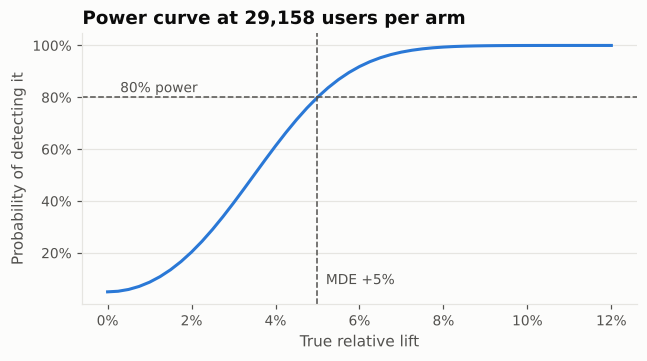

In [3]:
curve = power.power_curve(E["baseline_rate"], plan["n_per_arm"])
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(curve.relative_lift, curve.power, color=BLUE)
ax.axhline(0.8, color=INK_2, lw=1, ls="--"); ax.axvline(E["mde_relative"], color=INK_2, lw=1, ls="--")
ax.text(E["mde_relative"] + 0.002, 0.08, "MDE +5%", color=INK_2, fontsize=9)
ax.text(0.003, 0.82, "80% power", color=INK_2, fontsize=9)
pct(ax); pct(ax, "x")
ax.set_xlabel("True relative lift"); ax.set_ylabel("Probability of detecting it")
ax.set_title(f"Power curve at {plan['n_per_arm']:,} users per arm")
save(fig, "02_power_curve")

Read the left side of this curve too: a true +2.5% lift would be detected only ~30% of the
time. If the test comes back flat, "no effect" and "an effect too small to see" look the same.

## 2. So why run 28 days instead of 17?
The headline needs ~10 days of enrollment plus the 7-day window. We commit to longer, for three
reasons:

MDE at 22 enrollment days: all 3.3% · new 5.4% · returning 4.4%


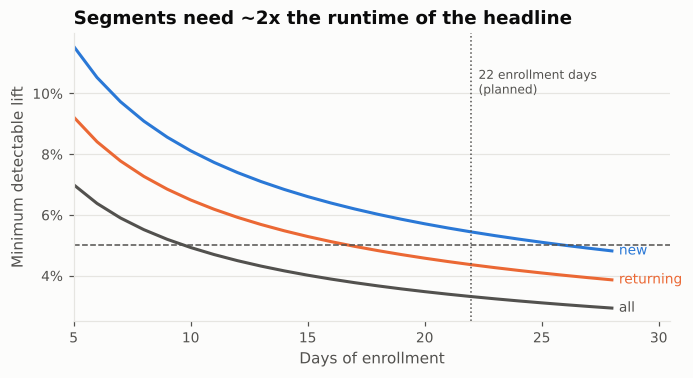

In [4]:
per_arm_per_day = E["daily_eligible_users"] / 2
days = np.arange(5, 29)
share_returning = 0.45   # from pre-period traffic mix
mde_all = [power.mde_given_n(E["baseline_rate"], int(d * per_arm_per_day)) for d in days]
mde_ret = [power.mde_given_n(0.22, int(d * per_arm_per_day * share_returning)) for d in days]
mde_new = [power.mde_given_n(0.13, int(d * per_arm_per_day * (1 - share_returning))) for d in days]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(days, mde_all, color=INK_2, label="all users")
ax.plot(days, mde_new, color=BLUE, label="new users only")
ax.plot(days, mde_ret, color=ORANGE, label="returning users only")
ax.axhline(0.05, color=INK_2, lw=1, ls="--")
ax.axvline(E["exposure_cohort_last_day"] + 1, color=INK_2, lw=1, ls=":")
ax.text(E["exposure_cohort_last_day"] + 1.3, 0.10, "22 enrollment days\n(planned)", color=INK_2, fontsize=8)
for y, lab, c in [(mde_all[-1], "all", INK_2), (mde_new[-1], "new", BLUE), (mde_ret[-1], "returning", ORANGE)]:
    ax.text(28.3, y, lab, color=c, fontsize=9, va="center")
pct(ax); ax.set_xlim(5, 30.5)
ax.set_xlabel("Days of enrollment"); ax.set_ylabel("Minimum detectable lift")
ax.set_title("Segments need ~2x the runtime of the headline")
save(fig, "02_mde_by_runtime")

print(f"MDE at 22 enrollment days: all {mde_all[17]:.1%} · new {mde_new[17]:.1%} · returning {mde_ret[17]:.1%}")

1. **Segments.** We pre-register three segment cuts: user type (new vs returning, where we have
   a mechanism to expect a difference: returning users already know what they want), platform,
   and city tier, with a Bonferroni correction for the 7 cells. Each user-type segment has about half the
   users, so its MDE is far larger. At 10 days, a segment effect below ~6-8% could hide.
2. **Novelty.** A shiny new card gets clicks in week 1. To separate novelty from a lasting
   effect we need users who have lived with the feature for 2-3 weeks.
3. **Weekly cycles.** Friday-Sunday ordering behaves differently. Whole weeks only.

Plan: **enroll for 22 days (days 0-21), observe each user for 7 days, end on day 28.**
Enrolled per arm ≈ 66k, which gives a headline MDE of ≈3.3% (segments ≈4-5%).

## 3. Stopping rule (pre-registered)
The dashboard will update daily, and people will look. Looking is fine; **acting** on an
unplanned look is not. We allow 4 weekly looks with O'Brien-Fleming boundaries (computed and
validated in notebook 04): stop early only if |z| crosses the boundary for that week.

| Look | Day | Stop if \|z\| > | Nominal p at that look |
|---|---|---|---|
| 1 | 7 | 4.04 | 0.00005 |
| 2 | 14 | 2.86 | 0.004 |
| 3 | 21 | 2.33 | 0.020 |
| 4 | 28 | 2.02 | 0.043 |

## 4. Decision rule (pre-registered)
* **Ship** if the primary metric is significant at the final look, guardrails are flat, and the
  **post-novelty** effect (sessions ≥7 days after first exposure) is not negative for any
  pre-registered segment.
* If a segment is significantly hurt: ship to the segments that benefit, keep a holdout.
* A segment "matters" only if the **interaction** test says its effect differs from the rest,
  not because one cell is significant and another isn't.
* Any cut not on the list (cuisine, time of day…) is exploratory: findings there need a new
  test, not a launch.